In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = "../data/raw/ratings_Beauty.csv"

df = pd.read_csv(
    DATA_PATH,
    names=["user_id", "item_id", "rating", "timestamp"]
)

df.head()

,user_id,item_id,rating,timestamp
0,A39HTATAQ9V7YF,0205616461,5.0,1369699200
1,A3JM6GV9MNOF9X,0558925278,3.0,1355443200
2,A1Z513UWSAAO0F,0558925278,5.0,1404691200
3,A1WMRR494NWEWV,0733001998,4.0,1382572800
4,A3IAAVS479H7M7,0737104473,1.0,1274227200


In [2]:
print("Количество взаимодействий:", len(df))
print("Количество пользователей:", df["user_id"].nunique())
print("Количество товаров:", df["item_id"].nunique())

print("\nПропущенные значения:")
print(df.isna().sum())

print("\nКоличество дубликатов:")
print(df.duplicated().sum())

Количество взаимодействий: 2023070
Количество пользователей: 1210271
Количество товаров: 249274

Пропущенные значения:
user_id      0
item_id      0
rating       0
timestamp    0
dtype: int64

Количество дубликатов:
0


In [3]:
user_interactions = df.groupby("user_id").size()

print("Статистика взаимодействий на пользователя:")
print(user_interactions.describe())

print("\nПользователей с минимум 3 взаимодействиями:",
      (user_interactions >= 3).sum())

print("Пользователей с менее чем 3 взаимодействиями:",
      (user_interactions < 3).sum())

Статистика взаимодействий на пользователя:
count    1.210271e+06
mean     1.671584e+00
std      2.531884e+00
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      2.000000e+00
max      3.890000e+02
dtype: float64

Пользователей с минимум 3 взаимодействиями: 146995
Пользователей с менее чем 3 взаимодействиями: 1063276


Распределение оценок:
rating
1.0     183784
2.0     113034
3.0     169791
4.0     307740
5.0    1248721
Name: count, dtype: int64


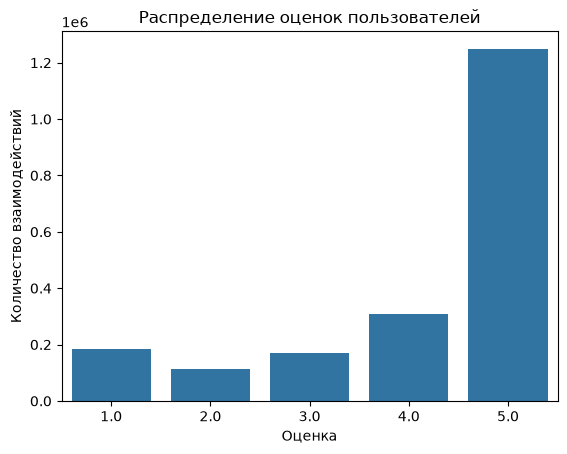

In [4]:
print("Распределение оценок:")
print(df["rating"].value_counts().sort_index())

sns.countplot(data=df, x="rating")
plt.title("Распределение оценок пользователей")
plt.xlabel("Оценка")
plt.ylabel("Количество взаимодействий")
plt.show()

In [5]:
DATA_PATH = "../data/raw/ratings_Beauty.csv"

with open(DATA_PATH, "r", encoding="utf-8") as file:
    for i, line in enumerate(file, 1):
        if i <= 10:
            print(f"Строка {i}: {repr(line)}")

Строка 1: 'A39HTATAQ9V7YF,0205616461,5.0,1369699200\n'
Строка 2: 'A3JM6GV9MNOF9X,0558925278,3.0,1355443200\n'
Строка 3: 'A1Z513UWSAAO0F,0558925278,5.0,1404691200\n'
Строка 4: 'A1WMRR494NWEWV,0733001998,4.0,1382572800\n'
Строка 5: 'A3IAAVS479H7M7,0737104473,1.0,1274227200\n'
Строка 6: 'AKJHHD5VEH7VG,0762451459,5.0,1404518400\n'
Строка 7: 'A1BG8QW55XHN6U,1304139212,5.0,1371945600\n'
Строка 8: 'A22VW0P4VZHDE3,1304139220,5.0,1373068800\n'
Строка 9: 'A3V3RE4132GKRO,130414089X,5.0,1401840000\n'
Строка 10: 'A327B0I7CYTEJC,130414643X,4.0,1389052800\n'


In [6]:
import csv

with open(DATA_PATH, "r", encoding="utf-8") as file:
    reader = csv.reader(file)

    for i, row in enumerate(reader, 1):
        if i <= 10:
            print(f"Строка {i}: {len(row)} столбца")

Строка 1: 4 столбца
Строка 2: 4 столбца
Строка 3: 4 столбца
Строка 4: 4 столбца
Строка 5: 4 столбца
Строка 6: 4 столбца
Строка 7: 4 столбца
Строка 8: 4 столбца
Строка 9: 4 столбца
Строка 10: 4 столбца


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2023070 entries, 0 to 2023069
Data columns (total 4 columns):
 #   Column     Dtype  
---  ------     -----  
 0   user_id    str    
 1   item_id    str    
 2   rating     float64
 3   timestamp  int64  
dtypes: float64(1), int64(1), str(2)
memory usage: 61.7 MB
